In this notebook we explore several ML approaches to classifying Alzheimer's disease (AD) and Parkinson's disease (PD) on the basis of vocal production features using the [Bridge2AI-Voice dataset](https://physionet.org/content/b2ai-voice/2.0.1/) 2.0.1 release. Newer releases use a different organization and may require changes to data loading and preprocessing portions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import bootstrap

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
from sklearn.feature_selection import SelectFromModel
from sklearn.base import BaseEstimator, MetaEstimatorMixin

#and this to make a tidier notebook
from sklearn.exceptions import ConvergenceWarning, FitFailedWarning
import warnings
warnings.filterwarnings(action="ignore",category=ConvergenceWarning)
warnings.filterwarnings(action="ignore",category=UserWarning)
warnings.filterwarnings(action="ignore",category=FitFailedWarning)

#I used numbergenerator.org to generate this number which will be my seed
rng = 48396

## load in and preprocess data

Described at length in their report, the Bridge2AI-Voice (B2AIv) dataset includes audio features derived from participant vocal production recordings; participant recruitment was initiated upon their presentation at "specialty clinics and institutions" and was based on membership in predetermined groups including "Neurological disorders", to which the AD and PD participants belong. It's worth pointing out the fact that, in this data release, Alzheimer's disease, dementia, and mild cognitive impairment are all folded into the same label. Whether this is justifiable for the present investigation is beyond my expertise! I'll refer to this category as "AD" going forward, but to be precise I am referring to the participants whose data bear this label. 

Therefore, the data we're working with here are the audio derivative feature data ("static features.tsv") associated with "AD", PD, and control participants (a subset of "phenotype.tsv"). 

NB: this work is all in the 2.0.1 data release, which is one release behind at time of writing. 

In [2]:
#be sure to change these to the locations of the phenotype and static_features tsvs if you'd like to run this yourself
pheno_loc = ...
stats_loc = ...

#load in
pheno = pd.read_csv(pheno_loc,sep='\t',header=0)
statics = pd.read_csv(stats_loc,sep='\t',header=0)

#subset participants according to AD, PD, or control group
pd_pids = pheno[pheno['diagnosis_parkinsons_gsd_category_1_calculation']=='Yes'].participant_id.unique()
ad_pids = pheno[pheno['alz_dementia_mci']=='Checked'][['diagnosis_alz_dementia_mci_dt','participant_id']].dropna().participant_id.unique()
ct_pids = pheno[pheno['is_control_participant']=='Yes'].participant_id.unique()

In [3]:
#make sure we don't have overlap
sum(np.isin(pd_pids,ad_pids)),sum(np.isin(pd_pids,ct_pids)),sum(np.isin(ad_pids,ct_pids))

(0, 0, 0)

In [4]:
#how many participants do we have in each condition?
print(f'{len(np.unique(pd_pids))} PD participants \n{len(np.unique(ad_pids))} AD participants \n{len(np.unique(ct_pids))} Control participants')

31 PD participants 
37 AD participants 
64 Control participants


In [5]:
#subset static features from participants of interest
pd_stats = statics[statics['participant_id'].isin(pd_pids)]
ad_stats = statics[statics['participant_id'].isin(ad_pids)]
ct_stats = statics[statics['participant_id'].isin(ct_pids)]

participants performed a variety of tasks for the B2AIv data. to honor our high-level aim, we opt to use the most naturalistic one: free speech. we'll tidy up the data a bit and assign labels here too

In [6]:
pd_fs = pd_stats[pd_stats['task_name'].isin(['Free-Speech','Free-speech-1','Free-speech-2','Free-speech-3'])][[i for i in pd_stats.columns if i not in ['session_id','task_name','transcription']]].dropna()
pd_fs['label'] = 1
ad_fs = ad_stats[ad_stats['task_name'].isin(['Free-Speech','Free-speech-1','Free-speech-2','Free-speech-3'])][[i for i in ad_stats.columns if i not in ['session_id','task_name','transcription']]].dropna()
ad_fs['label'] = 2
ct_fs = ct_stats[ct_stats['task_name'].isin(['Free-Speech','Free-speech-1','Free-speech-2','Free-speech-3'])][[i for i in ct_stats.columns if i not in ['session_id','task_name','transcription']]].dropna()
ct_fs['label'] = 0

some participants contribute multiple data to the set, so we split by participant to prevent leakage. We went with a 70/30 split to keep at least 10 diagnosis-bearing participants in the validation set for each diagnosis condition

In [7]:
train_parts_pd = pd_fs.participant_id.unique()[:int(np.floor(len(pd_fs.participant_id.unique())*.7))]
train_data_pd = pd_fs[pd_fs['participant_id'].isin(train_parts_pd)]
val_data_pd = pd_fs[~pd_fs['participant_id'].isin(train_parts_pd)]

train_parts_ad = ad_fs.participant_id.unique()[:int(np.floor(len(ad_fs.participant_id.unique())*.7))]
train_data_ad = ad_fs[ad_fs['participant_id'].isin(train_parts_ad)]
val_data_ad = ad_fs[~ad_fs['participant_id'].isin(train_parts_ad)]

#for each disease condition we sample the same amount of control participants
#then combine their data with the patient data to form our final training and validation sets
ct_train_parts_pd = ct_fs.participant_id.drop_duplicates().sample(len(train_parts_pd),random_state=rng).values
train_data_pd = pd.concat([train_data_pd,ct_fs[ct_fs.participant_id.isin(ct_train_parts_pd)]])

ct_train_parts_ad = ct_fs.participant_id.drop_duplicates().sample(len(train_parts_ad),random_state=rng).values
train_data_ad = pd.concat([train_data_ad,ct_fs[ct_fs.participant_id.isin(ct_train_parts_ad)]])

ct_val_parts_pd = ct_fs[~ct_fs['participant_id'].isin(ct_train_parts_pd)].participant_id.drop_duplicates().sample(len(val_data_pd.participant_id.unique()),random_state=rng).values
val_data_pd = pd.concat([val_data_pd,ct_fs[ct_fs.participant_id.isin(ct_val_parts_pd)]])

ct_val_parts_ad = ct_fs[~ct_fs['participant_id'].isin(ct_train_parts_ad)].participant_id.drop_duplicates().sample(len(val_data_ad.participant_id.unique()),random_state=rng).values
val_data_ad = pd.concat([val_data_ad,ct_fs[ct_fs.participant_id.isin(ct_val_parts_ad)]])

In [8]:
#how much data do we have in each condition?
print(f"""
PD: {len(train_data_pd.participant_id.unique())} participants giving {len(train_data_pd)} training samples 
    {len(val_data_pd.participant_id.unique())} participants giving {len(val_data_pd)} validation samples 

AD: {len(train_data_ad.participant_id.unique())} participants giving {len(train_data_ad)} training samples 
    {len(val_data_ad.participant_id.unique())} participants giving {len(val_data_ad)} validation samples
""")


PD: 42 participants giving 147 training samples 
    20 participants giving 75 validation samples 

AD: 50 participants giving 189 training samples 
    24 participants giving 93 validation samples



## ML benchmarking

Logistic regression, gradient boosting, support-vector machines, and neural networks are some common approaches to classification. PCA joins L1-penalized regression and ensemble selection methods as some common approaches to reducing the dimensionality of a predictor space to benefit the model of a classification problem. For these methods there also exists a considerable space of hyperparameters whose selection has consequence for the quality of the resulting model. We can't fully account for all of the possibilities in this work for practical reasons; rather, here we hope to survey some of the more-reasonable options.

For each disease, the basic approach will be to use sklearn GridSearchCV (with a stratified group K-fold split given the aforementioned participant/data contribution scheme) in the training set to build a model from a predetermined hyperparameter space. Then, the best model will be applied to held-out validation data for the disease in question. Finally, we'll return to the participant level by averating predictions for samples provided by the same partcipant into one score, then calculating a participant-wise AUROC for diagnostic classification using those scores.

In [9]:
def auc_statistic(positive_scores,negative_scores):
    '''
    auc function for use with scipy bootstrap()
    assumes "positive_scores" and "negative_scores" will be input seperately in bootstrap()
    this ended up being a mild hassle since some draws using the default function would keep only 1 class, 
    for which AUROC is undefined. so we resample from disease and control independently 
    
    Args:
        postive_scores:    model predictions for positive-class samples (in our case, diagnosed participants)
        negative_scores:   model predictions for negative-class samples (in our case, control participants)
    
    Returns:               the AUROC for the input predictions
    '''
    y_true = np.concatenate([np.ones(len(positive_scores)),np.zeros(len(negative_scores))])
    y_score = np.concatenate([positive_scores,negative_scores])
    return roc_auc_score(y_true,y_score)


def participant_auc(estimator, data, features, condition):
    '''
    calculate model performance on the participant level by aggregating recording-level predictions
    
    Args:
        estimator (sklearn estimator):   a fitted sklearn estimator
        data (pandas DataFrame):         all input data including participant id and labels
        features (list):                 the features in "data" our "estimator" will use for prediction
        condition (str):                 the condition we are predicting ('PD' or 'AD')
    
    Returns:
        agg_part_auc (float):            this estimator's participant-level auc score 
        all_preds_df (pandas df):        a dataframe of estimator's sample-level predictions on data
        agg_part_preds (pandas df):      this estimator's participant-level predictions, aggregated by averaging
        ci_lower (float):                the lower bound of the 95% CI for the aggregated participant-level predictions
        ci_upper (float):                the upper bound of the 95% CI for the aggregated participant-level predictions
        
    '''
    
    d = {'PD':1,
         'AD':2}   
    positive_label = d[condition]
    
    pred_data = data[features]
    
    if hasattr(estimator,'predict_proba'):
        positive_idx = np.where(estimator.classes_==positive_label)[0][0]
        scores = estimator.predict_proba(pred_data)[:,positive_idx]
    else:
        scores = estimator.decision_function(pred_data)
        if estimator.classes_[1]!=positive_label:
            scores = -scores
    
    
    
    #all the predictions we make on the inputs...
    all_preds_df = pd.DataFrame({'participant_id':data['participant_id'],
                          'label':data['label'].values,
                          'score':scores})

    #...averaged into participant-level predictions...
    agg_part_preds = all_preds_df.groupby('participant_id',as_index=False).agg(label=('label','first'),
                                                                    score=('score','mean'))
        
    #...then used to calculate an AUC... 
    agg_part_auc = roc_auc_score(agg_part_preds['label'],agg_part_preds['score'])
    
    #...and 95% CI    
    positive_scores = agg_part_preds.loc[agg_part_preds['label']==positive_label,'score'].values
    negative_scores = agg_part_preds.loc[agg_part_preds['label']==0,'score'].values
    
    ci_calc = bootstrap((positive_scores,negative_scores),auc_statistic,
                        confidence_level=0.95,method='BCa',random_state=rng)
    
    ci_lower = ci_calc.confidence_interval.low
    ci_upper = ci_calc.confidence_interval.high    
    
    return agg_part_auc, all_preds_df, agg_part_preds, ci_lower, ci_upper

In [10]:
def sklearn_cv(train_data,val_data,pipeline,params,
               score_string='roc_auc',drop_cols=['participant_id','label'],lab_col_str='label'):
    '''
    standardize model fitting and evaluation 
    
    Args: 
        train_data (pandas DataFrame):    training data
        pipeline (sklearn Pipeline):      sklearn pipeline object
        params (dict or list of dicts):   the parameter space to be explored in this CV
        score_string (str):               the name of an sklearn metric 
        drop_cols (list):                 the columns to be dropped from train_data 
        lab_col_str (str):                the name of the label column in train_data
    
    Returns:
        cv_scores (np Array):             the scores from each fold of the cv
        best_val (float):                 the best model's score on held-out data 
        gcv (sklearn GridSearchCV):       the grid search CV object  
        agg_part_preds (pandas df):       the dataframe of participantwise predictions used to calculate AUC
        {auc, ci_lower, ci_upper}:        a dictionary containing outputs from participant_auc() for this fitted model and val data
    '''
    
    groups = train_data.participant_id.to_numpy()
    gcv = GridSearchCV(estimator=pipeline,param_grid=params,cv=gkf,scoring=score_string)
    gcv.fit(train_data.drop(drop_cols,axis=1),train_data[lab_col_str],groups=groups)
    best_val = gcv.score(val_data.drop(drop_cols,axis=1),val_data[lab_col_str])
    
    #
    cv_results_df = pd.DataFrame(gcv.cv_results_)
    cv_scores = cv_results_df[cv_results_df['rank_test_score']==1][[i for i in cv_results_df if 'split' in i and 'test_score' in i]].values[0]
    best_cv = gcv.best_score_
    
    #calculate participantwise AUC
    auc, _, agg_part_preds, ci_lower, ci_upper = participant_auc(gcv.best_estimator_,val_data,
                                                 [i for i in val_data.columns if i not in drop_cols],
                                                 "PD" if val_data[lab_col_str].max() == 1 else "AD") #admittedly hacky
    
    
    
    return cv_scores, best_val, gcv, agg_part_preds, {'auc':auc,'ci_lower':ci_lower,'ci_upper':ci_upper}

In [11]:
#could use a more flexible tagging system to obviate the need to input results in a specific order 
#maybe highlight the best performing model in each plot?

def plot_results(llr_plot_results,
                 grb_plot_results,
                 svc_plot_results,
                 mlp_plot_results,
                 title_string,
                 ylabel_string = "AUROC",metric="AUC"):
    '''
    plot results given some outputs from our cv function
    
    Args:
        llr_plot_results, grb_plot_results, etc. (dict):  the plot_results outputs of run_tidy()
        title_string (str):                               title of the plot
        ylabel_string (str):                              title of the y-axis
        metric (str):                                     name of the metric being plotted

    '''
    
    llr_scores = llr_plot_results['cv_scores']
    llr_best_val = llr_plot_results['best_val']
    llr_part_auc = llr_plot_results['part_auc_res']['auc']
    llr_part_ci_upper = llr_plot_results['part_auc_res']['ci_upper']
    llr_part_ci_lower = llr_plot_results['part_auc_res']['ci_lower']
    plt.bar([1],np.mean(llr_scores),edgecolor='black',width=0.5,color='blue')
    plt.bar([1.5],llr_best_val,edgecolor='black',width=0.5,color='orange')
    plt.errorbar(x=2,y=llr_part_auc,
                 yerr=[[llr_part_auc-llr_part_ci_lower],[llr_part_ci_upper-llr_part_auc]],
                 fmt='o',color='red')
    
    
    grb_scores = grb_plot_results['cv_scores']
    grb_best_val = grb_plot_results['best_val']
    grb_part_auc = grb_plot_results['part_auc_res']['auc']
    grb_part_ci_upper = grb_plot_results['part_auc_res']['ci_upper']
    grb_part_ci_lower = grb_plot_results['part_auc_res']['ci_lower']
    plt.bar([5],np.mean(grb_scores),edgecolor='black',width=0.5,color='blue')
    plt.bar([5.5],grb_best_val,edgecolor='black',width=0.5,color='orange')
    plt.errorbar(x=6,y=grb_part_auc,
                 yerr=[[grb_part_auc-grb_part_ci_lower],[grb_part_ci_upper-grb_part_auc]],
                 fmt='o',color='red')
    
    svc_scores = svc_plot_results['cv_scores']
    svc_best_val = svc_plot_results['best_val']
    svc_part_auc = svc_plot_results['part_auc_res']['auc']
    svc_part_ci_upper = svc_plot_results['part_auc_res']['ci_upper']
    svc_part_ci_lower = svc_plot_results['part_auc_res']['ci_lower']
    plt.bar([9],np.mean(svc_scores),edgecolor='black',width=0.5,color='blue')
    plt.bar([9.5],svc_best_val,edgecolor='black',width=0.5,color='orange')
    plt.errorbar(x=10,y=svc_part_auc,
                 yerr=[[svc_part_auc-svc_part_ci_lower],[svc_part_ci_upper-svc_part_auc]],
                 fmt='o',color='red')
    
    mlp_scores = mlp_plot_results['cv_scores']
    mlp_best_val = mlp_plot_results['best_val']
    mlp_part_auc = mlp_plot_results['part_auc_res']['auc']
    mlp_part_ci_upper = mlp_plot_results['part_auc_res']['ci_upper']
    mlp_part_ci_lower = mlp_plot_results['part_auc_res']['ci_lower']
    plt.bar([13],np.mean(mlp_scores),edgecolor='black',width=0.5,color='blue',label='Sample-wise CV mean AUC')
    plt.bar([13.5],mlp_best_val,edgecolor='black',width=0.5,color='orange',label='Sample-wise validation AUC')
    plt.errorbar(x=14,y=mlp_part_auc,
                 yerr=[[mlp_part_auc-mlp_part_ci_lower],[mlp_part_ci_upper-mlp_part_auc]],
                 fmt='o',color='red',label='Participant-wise AUC & 95% CI')
    
    if metric == "AUC":
        plt.axhline(y=0.5, color='black', linestyle='--', linewidth=1.5, label='Chance performance')
    
    plt.xticks([0.5,5,9.5,14],
[
f'Logistic Regression \n sample-wise mean CV {metric}: {np.mean(llr_scores):.2f} \n \
sample-wise validation {metric}: {llr_best_val:.2f} \n \
participant-wise {metric}: {llr_part_auc:.2f} [{llr_part_ci_lower:.2f},{llr_part_ci_upper:.2f}]',
                              
f'Gradient Boosting \n sample-wise mean CV {metric}: {np.mean(grb_scores):.2f} \n \
sample-wise validation {metric}: {grb_best_val:.2f} \n \
participant-wise {metric}: {grb_part_auc:.2f} [{grb_part_ci_lower:.2f},{grb_part_ci_upper:.2f}]',
                              
f'SVC \n sample-wise mean CV {metric}: {np.mean(svc_scores):.2f} \n \
sample-wise validation {metric}: {svc_best_val:.2f} \n \
participant-wise {metric}: {svc_part_auc:.2f} [{svc_part_ci_lower:.2f},{svc_part_ci_upper:.2f}]',
                              
f'MLP \n sample-wise mean CV {metric}: {np.mean(mlp_scores):.2f} \n \
sample-wise validation {metric}: {mlp_best_val:.2f} \n \
participant-wise {metric}: {mlp_part_auc:.2f} [{mlp_part_ci_lower:.2f},{mlp_part_ci_upper:.2f}]'
])

    
    plt.xticks(rotation=45)
    plt.tick_params(axis='x', bottom=False)

    plt.legend(bbox_to_anchor=[1.7,1],markerscale=.75)
    plt.ylim([0,1.1])
    plt.title(title_string)
    plt.ylabel(ylabel_string)


In [12]:
def run_tidy(train_data,val_data,pipeline,params,metric):
    '''
    i wrote this to help cut down on text required to actually run these. 
    the inputs are the same as sklearn_cv, but the outputs have been loosely organized
    '''
    

    cv_scores, best_val, gcv_object, agg_part_preds, part_auc_res = sklearn_cv(train_data,val_data,
                                                                               pipeline,params,metric)

    plot_results = {'cv_scores':cv_scores,
                    'best_val':best_val,
                    'part_auc_res':part_auc_res}    
    
    analysis_results = {'gcv_object':gcv_object,
                       'agg_part_preds':agg_part_preds}
    
    return plot_results, analysis_results

next we set forth the group KFold object, sklearn pipelines, and hyperparameter grids

In [13]:
#params 'n pipelines
gkf = StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=rng)
C_grid = [1e-2,1e-1,1,1e1,1e2]
a_grid = [1e-5,1e-4,1e-3,1e-2,1e-1]
mlp_shapes = [(16,),(64,),(32,32),(64,32,16),
              (32,32,16,16),(128,64,32,16,8),
              (16,16,16,16,16,16,16)]

#elastic net logistic
llr_pipeline = Pipeline([('scaler',StandardScaler()),
                         ('llr',LogisticRegression(penalty='elasticnet',
                                                   solver='saga',
                                                   max_iter=1000,
                                                   random_state=rng))])
llr_params = {'llr__C':C_grid,
              'llr__l1_ratio':[0,0.25,0.5,0.75,1]}


#support-vector classifier 
svc_pipeline = Pipeline([('scaler',StandardScaler()),('svc',SVC())])
svc_params = [
              {'svc__kernel':['linear'], 
               'svc__C':C_grid},              
              {'svc__kernel':['rbf'],
               'svc__C':C_grid,
               'svc__gamma':['scale']},
              {'svc__kernel':['poly'],
               'svc__C':C_grid,
               'svc__gamma':['scale'],
               'svc__degree':[2,3],
               'svc__coef0':[0,1]}
             ]


#gradient boosting 
grb_pipeline = Pipeline([('grb',GradientBoostingClassifier(random_state=rng))])
grb_schedules = [(0.1,100),(0.05,200),(0.02,500)]
grb_params = [{'grb__max_features':[None,'sqrt'],
              'grb__learning_rate':[learning_rate],
              'grb__n_estimators':[n_estimators],
              'grb__subsample':[0.6,1],
              'grb__min_samples_leaf':[0.05,0.1,0.2],
              'grb__max_depth':[1,2,3]} 
               for learning_rate, n_estimators in grb_schedules]

#MLP
mlp_pipeline = Pipeline([('scaler',StandardScaler()),
                         ('mlp',MLPClassifier(max_iter=2000,solver='lbfgs',
                                              random_state=rng))])
mlp_params = {'mlp__hidden_layer_sizes':mlp_shapes,
              'mlp__activation':['relu','tanh'],
              'mlp__alpha':a_grid}


# baselines

First we'll run everything naively

In [14]:
llr_pd_baseline, _ = run_tidy(train_data_pd,val_data_pd,llr_pipeline,llr_params,'roc_auc')
grb_pd_baseline, _ = run_tidy(train_data_pd,val_data_pd,grb_pipeline,grb_params,'roc_auc')
svc_pd_baseline, _ = run_tidy(train_data_pd,val_data_pd,svc_pipeline,svc_params,'roc_auc')
mlp_pd_baseline, _ = run_tidy(train_data_pd,val_data_pd,mlp_pipeline,mlp_params,'roc_auc')

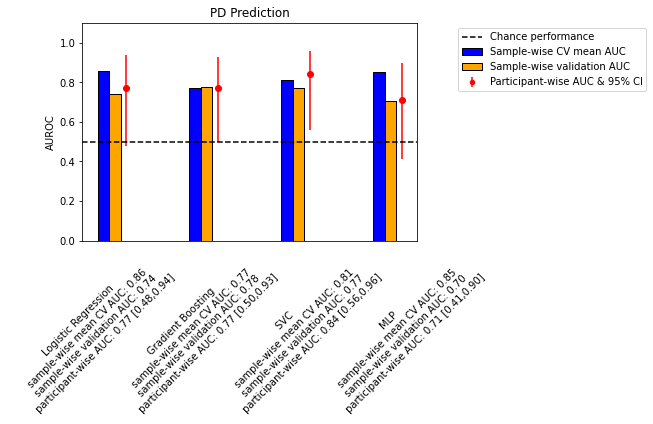

In [15]:
plot_results(llr_pd_baseline,grb_pd_baseline,svc_pd_baseline,mlp_pd_baseline,'PD Prediction')

In [16]:
llr_ad_baseline, _ = run_tidy(train_data_ad,val_data_ad,llr_pipeline,llr_params,'roc_auc')
grb_ad_baseline, _ = run_tidy(train_data_ad,val_data_ad,grb_pipeline,grb_params,'roc_auc')
svc_ad_baseline, _ = run_tidy(train_data_ad,val_data_ad,svc_pipeline,svc_params,'roc_auc')
mlp_ad_baseline, _ = run_tidy(train_data_ad,val_data_ad,mlp_pipeline,mlp_params,'roc_auc')

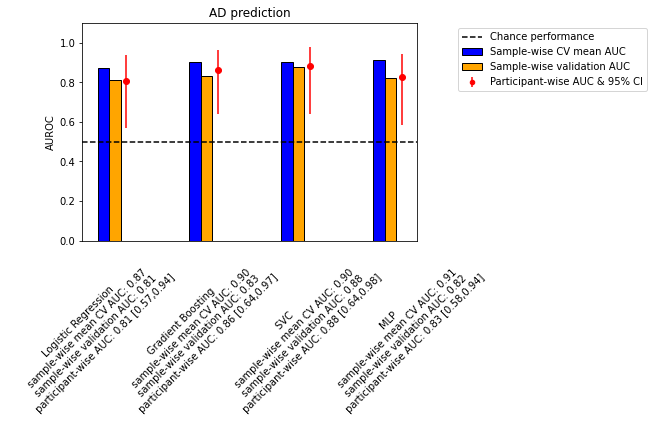

In [17]:
plot_results(llr_ad_baseline,grb_ad_baseline,svc_ad_baseline,mlp_ad_baseline,'AD prediction')

# Dimensionality reduction: PCA

Next, we'll use PCA to try leveraging some latent structure in these data against the classification problem

In [18]:
#we can try keeping PCs explaining different proportions of the features' variance as part of our search
pca_step = [('pca',PCA(svd_solver='full',random_state=rng))]
pca_step_params = {'pca__n_components':[0.6,0.85,0.95]}

#we can insert the PCA into our existing pipelines straightforwardly
llr_pca_pipeline = Pipeline([llr_pipeline.steps[0]]+pca_step+llr_pipeline.steps[1:])
svc_pca_pipeline = Pipeline([svc_pipeline.steps[0]]+pca_step+svc_pipeline.steps[1:])
grb_pca_pipeline = Pipeline([('scaler',StandardScaler())]+pca_step+grb_pipeline.steps)
mlp_pca_pipeline = Pipeline([mlp_pipeline.steps[0]]+pca_step+mlp_pipeline.steps[1:])

#and with similar ease add our PCA hyperparameter to our model grids
llr_pca_params = llr_params | pca_step_params
svc_pca_params = [i | pca_step_params for i in svc_params]
grb_pca_params = [i | pca_step_params for i in grb_params]
mlp_pca_params = mlp_params | pca_step_params

## PD classification w/ PCA

In [19]:
#then run
llr_pd_pca, _ = run_tidy(train_data_pd,val_data_pd,llr_pca_pipeline,llr_pca_params,'roc_auc')
grb_pd_pca, _ = run_tidy(train_data_pd,val_data_pd,grb_pca_pipeline,grb_pca_params,'roc_auc')
svc_pd_pca, _ = run_tidy(train_data_pd,val_data_pd,svc_pca_pipeline,svc_pca_params,'roc_auc')
mlp_pd_pca, _ = run_tidy(train_data_pd,val_data_pd,mlp_pca_pipeline,mlp_pca_params,'roc_auc')

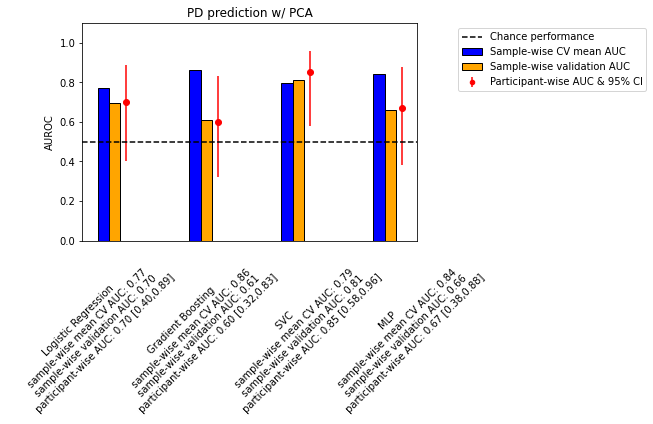

In [20]:
#
plot_results(llr_pd_pca,grb_pd_pca,svc_pd_pca,mlp_pd_pca,'PD prediction w/ PCA')

## AD classification w/ PCA

In [21]:
llr_ad_pca, _ = run_tidy(train_data_ad,val_data_ad,llr_pca_pipeline,llr_pca_params,'roc_auc')
grb_ad_pca, _ = run_tidy(train_data_ad,val_data_ad,grb_pca_pipeline,grb_pca_params,'roc_auc')
svc_ad_pca, _ = run_tidy(train_data_ad,val_data_ad,svc_pca_pipeline,svc_pca_params,'roc_auc')
mlp_ad_pca, _ = run_tidy(train_data_ad,val_data_ad,mlp_pca_pipeline,mlp_pca_params,'roc_auc')

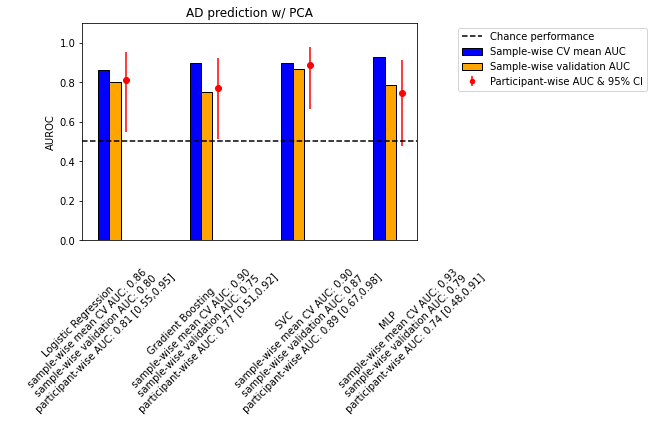

In [22]:
#
plot_results(llr_ad_pca,grb_ad_pca,svc_ad_pca,mlp_ad_pca,'AD prediction w/ PCA')

# Dimensionality reduction: LASSO feature selection

We have regularized logistic regression models pulling double duty here - we're still interested in their performance on this task, but now we'll also ask whether adding LASSO regression for feature selection will improve other model types' performance

In [23]:
#as before we'll make a new step...
l1_selection_model = LogisticRegression(penalty='l1',solver='liblinear',max_iter=1000,random_state=rng)
l1_selection_params = {'l1_selection__estimator__C':C_grid}
l1_selection_step = [('l1_selection',SelectFromModel(l1_selection_model,prefit=False,threshold=1e-5))]

#...and prepend it to the existing pipelines
svc_l1r_pipeline = Pipeline([svc_pipeline.steps[0]]+l1_selection_step+svc_pipeline.steps[1:])
grb_l1r_pipeline = Pipeline([('scaler',StandardScaler())]+l1_selection_step+grb_pipeline.steps)
mlp_l1r_pipeline = Pipeline([mlp_pipeline.steps[0]]+l1_selection_step+mlp_pipeline.steps[1:])

#we'll also need to add our regularization strength grid to the existing pipeline parameter grids
svc_l1r_params = [i | l1_selection_params for i in svc_params]
grb_l1r_params = [i | l1_selection_params for i in grb_params]
mlp_l1r_params = mlp_params | l1_selection_params

## PD classification w/ LASSO feature selection

In [24]:
#adding l1 regularization to the elastic net model would be redundant but we run these augmented versions of the rest
grb_pd_l1r, _ = run_tidy(train_data_pd,val_data_pd,grb_l1r_pipeline,grb_l1r_params,'roc_auc')
svc_pd_l1r, _ = run_tidy(train_data_pd,val_data_pd,svc_l1r_pipeline,svc_l1r_params,'roc_auc')
mlp_pd_l1r, _ = run_tidy(train_data_pd,val_data_pd,mlp_l1r_pipeline,mlp_l1r_params,'roc_auc')

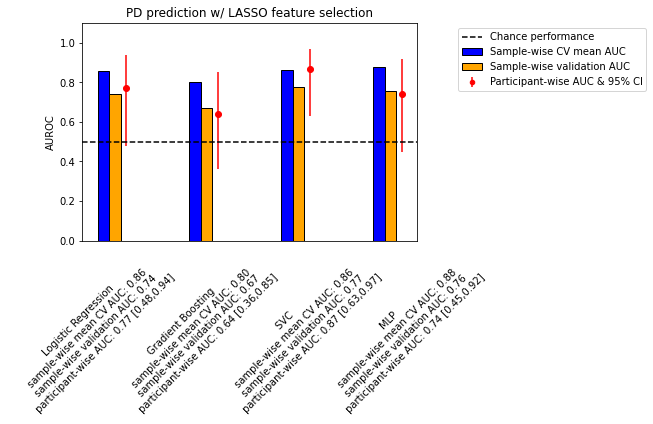

In [25]:
plot_results(llr_pd_baseline,grb_pd_l1r,svc_pd_l1r,mlp_pd_l1r,'PD prediction w/ LASSO feature selection')

## AD classification w/ LASSO feature selection

In [26]:
grb_ad_l1r, _ = run_tidy(train_data_ad,val_data_ad,grb_l1r_pipeline,grb_l1r_params,'roc_auc')
svc_ad_l1r, _ = run_tidy(train_data_ad,val_data_ad,svc_l1r_pipeline,svc_l1r_params,'roc_auc')
mlp_ad_l1r, _ = run_tidy(train_data_ad,val_data_ad,mlp_l1r_pipeline,mlp_l1r_params,'roc_auc')

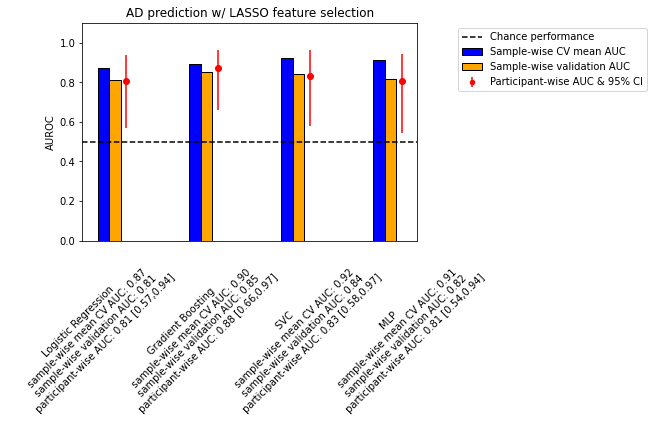

In [27]:
plot_results(llr_ad_baseline,grb_ad_l1r,svc_ad_l1r,mlp_ad_l1r,'AD prediction w/ LASSO feature selection')

# Dimensionality Reduction: boosting feature selection

this actually turned out to be a huge hassle. naively we could use GradientBoostingClassifier() with SelectFromModel() as we did with LASSO selection, but the default impurity-based feature importance calculation for such models has various relevant weaknesses. The prevailing alternative - permutation importance - turns out to be weak in the presence of collinear features...

Text(0.5, 1.0, 'correlations among features in B2AIv dataset \n (I removed the x and y tick labels for crowding)')

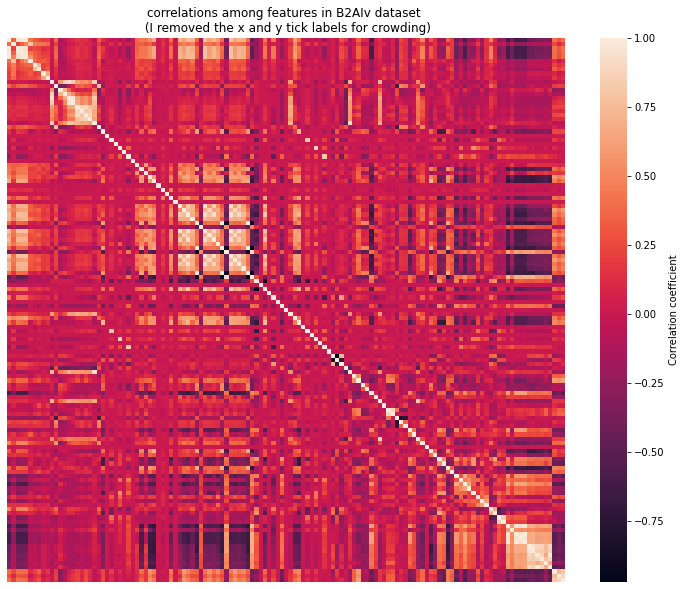

In [28]:
plt.figure(figsize=(12.5,10))

sns.heatmap(statics[[i for i in train_data_pd.drop(['participant_id','label'],axis=1).columns]].corr(),
           cbar_kws={"label": "Correlation coefficient"})
plt.xticks([])
plt.yticks([])
plt.title('correlations among features in B2AIv dataset \n (I removed the x and y tick labels for crowding)')

...of which, perhaps not surprisingly, we have a few!

The prescribed solution appears to be [using a different feature selection procedure altogether](https://scikit-learn.org/stable/auto_examples/inspection/plot_permutation_importance_multicollinear.html). Fair enough; however, I set out to try a tree ensemble for feature selection, and so I'll settle for permutation importance. Incorporating permutation importance in a SelectFromModel() call requires a custom implementation

In [29]:
class PermutationImportanceSelector(BaseEstimator,MetaEstimatorMixin):
    '''
    intended for use with GradientBoostingClassifier() estimators, 
    this will reproduce the wrapped model with its default feature importances replaced with permutation importances
    
    Args:
        estimator (sklearn estimator):    an sklearn estimator that will have a feature_importances_ attribute when fit
    '''    
    def __init__(self,estimator):
        self.estimator = estimator
        
    def fit(self, X, y, **fit_params):
        self.estimator_ = self.estimator.fit(X,y,**fit_params)
        
        permutation_importance_result = permutation_importance(self.estimator_,X,y,scoring='roc_auc',random_state=rng)
        self.feature_importances_ = np.clip(permutation_importance_result.importances_mean,a_min=0,a_max=None) #keep >0
        return self
    
    def predict(self, X):
        return self.estimator_.predict(X)
    
    def predict_proba(self, X):
        return self.estimator_.predict_proba(X)
    

In [30]:
#one additional step here to wrap the base gradient boosting model in our permutation importance selector
#i didn't want to run a seperate hyperparameter search on the feature selection model but that is clearly an option here
grb_selection_base = GradientBoostingClassifier(n_estimators=200,learning_rate=0.05,max_depth=2,min_samples_leaf=0.1,random_state=rng)
grb_selection_model = PermutationImportanceSelector(grb_selection_base)

#we will however add selection thresholds to the search
grb_selection_step = [('grb_selection',SelectFromModel(grb_selection_model,prefit=False,threshold='mean'))]
grb_selection_step_params = {'grb_selection__threshold':['mean','median','1.5*mean']}

#then the rest should be familiar
llr_gbs_pipeline = Pipeline(grb_selection_step+llr_pipeline.steps)
svc_gbs_pipeline = Pipeline(grb_selection_step+svc_pipeline.steps)
grb_gbs_pipeline = Pipeline(grb_selection_step+grb_pipeline.steps)
mlp_gbs_pipeline = Pipeline(grb_selection_step+mlp_pipeline.steps)

llr_gbs_params = llr_params | grb_selection_step_params
svc_gbs_params = [i | grb_selection_step_params for i in svc_params]
grb_gbs_params = [i | grb_selection_step_params for i in grb_params]
mlp_gbs_params = mlp_params | grb_selection_step_params

## PD classification w/ boosting feature selection 

In [31]:
llr_pd_gbs, _ = run_tidy(train_data_pd,val_data_pd,llr_gbs_pipeline,llr_gbs_params,'roc_auc')
#unlike the case of adding an l1 feature selection step to an elastic net model, 
#there is a meaningful addition to be made using one tree ensemble to select features for another
grb_pd_gbs, _ = run_tidy(train_data_pd,val_data_pd,grb_gbs_pipeline,grb_gbs_params,'roc_auc')
svc_pd_gbs, _ = run_tidy(train_data_pd,val_data_pd,svc_gbs_pipeline,svc_gbs_params,'roc_auc')
mlp_pd_gbs, _ = run_tidy(train_data_pd,val_data_pd,mlp_gbs_pipeline,mlp_gbs_params,'roc_auc')

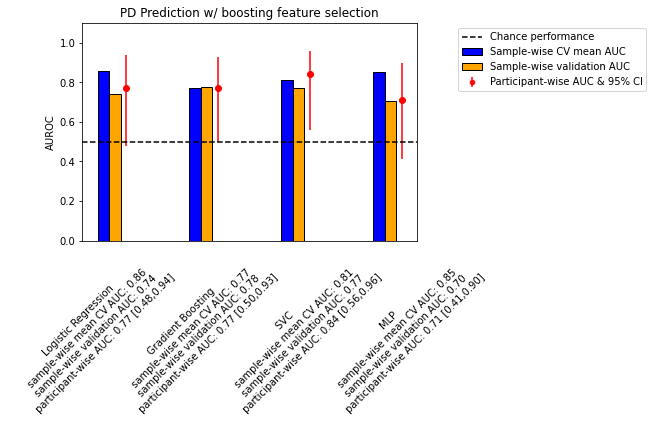

In [32]:
plot_results(llr_pd_gbs,grb_pd_gbs,svc_pd_gbs,mlp_pd_gbs,'PD Prediction w/ boosting feature selection')

## AD classification w/ boosting feature selection 

In [33]:
llr_ad_gbs, _ = run_tidy(train_data_ad,val_data_ad,llr_gbs_pipeline,llr_gbs_params,'roc_auc')
#unlike the case of adding an l1 feature selection step to an elastic net model, 
#there is a meaningful addition to be made using one tree ensemble to select features for another
grb_ad_gbs, _ = run_tidy(train_data_ad,val_data_ad,grb_gbs_pipeline,grb_gbs_params,'roc_auc')
svc_ad_gbs, _ = run_tidy(train_data_ad,val_data_ad,svc_gbs_pipeline,svc_gbs_params,'roc_auc')
mlp_ad_gbs, _ = run_tidy(train_data_ad,val_data_ad,mlp_gbs_pipeline,mlp_gbs_params,'roc_auc')

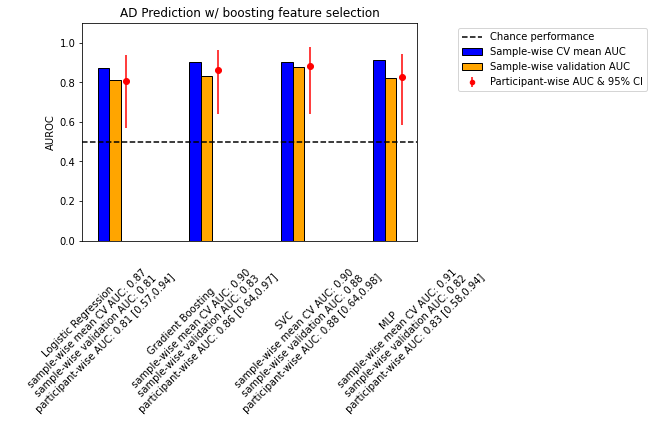

In [34]:
plot_results(llr_ad_gbs,grb_ad_gbs,svc_ad_gbs,mlp_ad_gbs,'AD Prediction w/ boosting feature selection')

# The Result:

Under these conditions,

Our best model for PD was the LASSO + support-vector classifier model with participant-wise AUC 0.87

Our best model for AD was the PCA + support-vector classifier model with participant-wise AUC 0.89